# Predicting Drought Before the Rains Fail

## Seasonal Climatology Baseline — Tanzania (1981–2025)

**Research Group 3 | District-level severe meteorological drought**

This notebook contains the complete reproducible baseline study: dataset verification, historical drought analysis, mathematical specification, worked calculations, retrospective forecasts, performance evaluation and conclusions. The only forecasting model is unweighted Seasonal Climatology.

Run cells sequentially using **Run → Run All Cells**. Results and figures are written to `outputs/`.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "data" / "processed" / "tma_baseline_inputs.csv.gz").is_file():
    raise FileNotFoundError("Open JupyterLab from the project directory and check data/processed/.")
sys.path.insert(0, str(ROOT / "src"))
OUT = ROOT / "outputs"
for folder in ("figures", "maps", "metrics", "predictions", "tables"):
    (OUT / folder).mkdir(parents=True, exist_ok=True)

from group3_climatology.config import INPUT, OUTPUT, SPI_FIELD, GEOGRAPHY
from group3_climatology.data import load_data, audit_data, missing_by_year
from group3_climatology.historical import classify, historical_tables, drought_episodes, northern_case_study
from group3_climatology.plots import (plot_annual, plot_districts, plot_monthly,
    plot_episode_duration, plot_geographic, plot_case_study, plot_confusion,
    plot_probability_bins)
from group3_climatology.baseline import forecast_table, climatology_snapshot, inspect_forecast
from group3_climatology.evaluation import (validation_threshold, evaluation_by_period,
    onset_warnings, score_forecasts, monthly_case_study)
from group3_climatology.pipeline import run_pipeline

data = load_data(INPUT)
print(f"Loaded {len(data):,} district-month records from {data.month.min():%Y-%m} to {data.month.max():%Y-%m}.")

Loaded 81,000 district-month records from 1981-01 to 2025-12.


## 1. Data exploration

**Objective.** Examine the geographical, temporal and variable coverage of the verified TMA district-month table. The repository includes a compact lossless extraction of the fields required for this baseline. The original source archive is not required for ordinary notebook execution.

In [2]:
print(f"Records: {len(data):,} | Districts: {data.district_id.nunique()} | Regions: {data.region.nunique()}")
print(f"Period: {data.month.min():%Y-%m} to {data.month.max():%Y-%m}")
display(data.head(8))

Records: 81,000 | Districts: 150 | Regions: 31
Period: 1981-01 to 2025-12


,district_id,region,district,month,chirps3_rain_mm,rain_3month_mm,spi3_gamma_ref1981_2010,severe_spi3_this_month,wfp_modis_ndvi
0,0101,Dodoma,Kondoa,1981-01-01,66.49445,NaN,NaN,NaN,NaN
1,0101,Dodoma,Kondoa,1981-02-01,123.75640,NaN,NaN,NaN,NaN
2,0101,Dodoma,Kondoa,1981-03-01,124.43801,314.68886,-0.745176,0.0,NaN
3,0101,Dodoma,Kondoa,1981-04-01,163.35419,411.54861,0.528824,0.0,NaN
4,0101,Dodoma,Kondoa,1981-05-01,34.67539,322.46760,0.384545,0.0,NaN
5,0101,Dodoma,Kondoa,1981-06-01,4.64276,202.67234,0.758997,0.0,NaN
6,0101,Dodoma,Kondoa,1981-07-01,1.32080,40.63895,-0.050633,0.0,NaN
7,0101,Dodoma,Kondoa,1981-08-01,4.52032,10.48387,1.606326,0.0,NaN


### Variables used in this study

| Variable | Interpretation | Unit |
|---|---|---|
| `district_id`, `region`, `district` | Geographic identifiers | Text |
| `month` | Observation month | Date |
| `chirps3_rain_mm` | Monthly CHIRPS precipitation | mm/month |
| `rain_3month_mm` | Three-month cumulative rainfall | mm/3 months |
| `spi3_gamma_ref1981_2010` | Rainfall-standardized SPI-3, reference 1981–2010 | Dimensionless |
| `severe_spi3_this_month` | Severe meteorological drought label | Binary |
| `wfp_modis_ndvi` | Satellite vegetation indicator; historical context only | Dimensionless |

**Baseline inputs:** district, target calendar month and prior severe SPI-3 labels. Rainfall and NDVI are inspected but are not baseline predictors.

In [3]:
print("Column types and missing values")
display(pd.DataFrame({"type": data.dtypes.astype(str),"nonmissing": data.count(),"missing": data.isna().sum()}))
coverage = missing_by_year(data)
display(coverage.head(6))
display(coverage.tail(6))

Column types and missing values


,type,nonmissing,missing
district_id,object,81000,0
region,object,81000,0
district,object,81000,0
month,datetime64[ns],81000,0
chirps3_rain_mm,float64,81000,0
rain_3month_mm,float64,80700,300
spi3_gamma_ref1981_2010,float64,80700,300
severe_spi3_this_month,float64,80700,300
wfp_modis_ndvi,float64,21432,59568


,year,districts,rainfall_valid,spi3_valid,ndvi_valid,spi3_missing
0,1981,150,1800,1500,0,300
1,1982,150,1800,1800,0,0
2,1983,150,1800,1800,0,0
3,1984,150,1800,1800,0,0
4,1985,150,1800,1800,0,0
5,1986,150,1800,1800,0,0


,year,districts,rainfall_valid,spi3_valid,ndvi_valid,spi3_missing
39,2020,150,1800,1800,912,0
40,2021,150,1800,1800,912,0
41,2022,150,1800,1800,912,0
42,2023,150,1800,1800,912,0
43,2024,150,1800,1800,912,0
44,2025,150,1800,1800,912,0


### Temporal coverage and satellite limitations

SPI-3 requires a rolling three-month accumulation; the first two months have undefined SPI-3. NDVI begins later and covers fewer districts. Satellite observations do not enter the baseline frequency model.

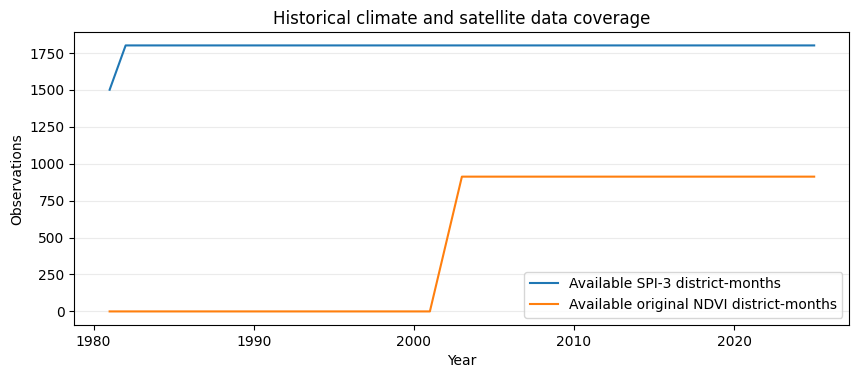

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(coverage.year, coverage.spi3_valid, label="Available SPI-3 district-months")
ax.plot(coverage.year, coverage.ndvi_valid, label="Available original NDVI district-months")
ax.set(xlabel="Year", ylabel="Observations", title="Historical climate and satellite data coverage")
ax.legend(); ax.grid(axis="y", alpha=.25)
fig.savefig(OUT / "figures" / "data_coverage_by_year.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

### Data interpretation

The dataset uses 2022 administrative district boundaries throughout the 1981–2025 period. Pre-2022 district labels therefore describe conditions assigned retrospectively to a fixed geography. The SPI-3 index was produced with a fixed 1981–2010 reference period and is not recomputed in this baseline study.

## 2. Data quality control

**Objective.** Verify district-month uniqueness, complete temporal keys, rainfall plausibility, missing SPI observations and internal consistency of supplied severe-drought labels.

In [5]:
report = audit_data(data, strict=True)
display(pd.DataFrame(report.items(), columns=["Check", "Result"]))
(OUT / "metrics" / "data_quality.json").write_text(json.dumps(report, indent=2), encoding="utf-8")

,Check,Result
0,district_month_records,81000
1,districts,150
2,regions,31
3,first_month,1981-01
4,last_month,2025-12
5,calendar_months,540
6,valid_spi3,80700
7,missing_spi3,300
8,severe_spi3_months,4364
9,extreme_spi3_months,1399


577

### Consistency rule

For each month with defined SPI-3, the source label must satisfy:

$$Y_{d,t}=\mathbb{1}\{\mathrm{SPI3}_{d,t}\leq -1.5\}.$$

Records with undefined SPI-3 are excluded from the drought-frequency denominator. Rainfall values are checked for physically impossible negatives; exceptionally high monthly rainfall totals are flagged for inspection rather than removed automatically.

In [6]:
print("SPI-3 defined:", data[SPI_FIELD].notna().sum())
print("SPI-3 undefined:", data[SPI_FIELD].isna().sum())
print("Rainfall greater than 1000 mm/month:", int(data.chirps3_rain_mm.gt(1000).sum()))
print("Rainfall exactly zero:", int(data.chirps3_rain_mm.eq(0).sum()))
print("Missing SPI-3 by calendar month:")
display(data.loc[data[SPI_FIELD].isna()].groupby(data.month.dt.strftime("%Y-%m")).size().rename("missing_districts").to_frame())

SPI-3 defined: 80700
SPI-3 undefined: 300
Rainfall greater than 1000 mm/month: 24
Rainfall exactly zero: 203
Missing SPI-3 by calendar month:


,missing_districts
month,
1981-01,150
1981-02,150


### Source limitations

A valid SPI-3 label verifies internal consistency with the supplied threshold; it does not validate rainfall against an independent station network. No claim about livestock losses or crop production can be derived from an SPI label alone.

In [7]:
qc_table = pd.DataFrame([report])
qc_table.to_csv(OUT / "metrics" / "data_quality_summary.csv", index=False)
assert report["duplicate_district_month"] == 0
assert report["spi_threshold_label_mismatches"] == 0
print("All required data-integrity checks passed.")

All required data-integrity checks passed.


## 3. Historical drought reconstruction

**Objective.** Locate drought occurrences, quantify their frequency and magnitude, and reconstruct consecutive drought episodes from 1981 to 2025.

Classification uses the supplied rainfall-based SPI-3 index:

- Moderate drought: $-1.5 < \mathrm{SPI3} \leq -1.0$
- Severe drought: $-2.0 < \mathrm{SPI3} \leq -1.5$
- Extreme drought: $\mathrm{SPI3}\leq-2.0$

For baseline evaluation, the severe-event indicator includes both severe and extreme months: $\mathrm{SPI3}\leq-1.5$.

In [8]:
classified = classify(data)
tables = historical_tables(data)
severe_episodes = drought_episodes(data, threshold=-1.5)
all_drought_episodes = drought_episodes(data, threshold=-1.0)
print("Valid SPI-3 observations:", classified.spi3_gamma_ref1981_2010.notna().sum())
print("Severe district-months:", int(classified.is_severe.sum()))
print("Severe episodes:", len(severe_episodes))
print("Longest severe episode (months):", severe_episodes.duration_months.max())

Valid SPI-3 observations: 80700
Severe district-months: 4364
Severe episodes: 2859
Longest severe episode (months): 7


### Where did drought occur most often?

Frequency is computed as severe district-months divided by valid district-months. The result is a meteorological-drought frequency, not a measure of people affected.

,district_id,region,district,valid_spi_months,severe_months,drought_months,extreme_months,lowest_spi3,average_rainfall_mm,severe_frequency
89,1606,Kigoma,Kakonko,538,46.0,88.0,14.0,-3.181148,96.254818,0.085502
97,1805,Kagera,Ngara,538,44.0,81.0,14.0,-3.098309,90.357697,0.081784
103,1904,Mwanza,Kwimba,538,44.0,84.0,15.0,-3.144335,81.631318,0.081784
131,2502,Geita,Nyang'hwale,538,43.0,78.0,12.0,-3.278508,90.479019,0.079926
134,2505,Geita,Chato,538,43.0,81.0,18.0,-2.713516,94.113686,0.079926
96,1804,Kagera,Biharamulo,538,43.0,77.0,23.0,-2.650962,97.120334,0.079926
108,2002,Mara,Serengeti,538,43.0,76.0,18.0,-3.273697,84.433560,0.079926
86,1603,Kigoma,Kigoma,538,43.0,95.0,13.0,-2.737734,114.591813,0.079926
101,1902,Mwanza,Magu,538,41.0,76.0,14.0,-2.660268,97.930134,0.076208
105,1906,Mwanza,Ilemela,538,41.0,82.0,16.0,-2.837977,98.193753,0.076208


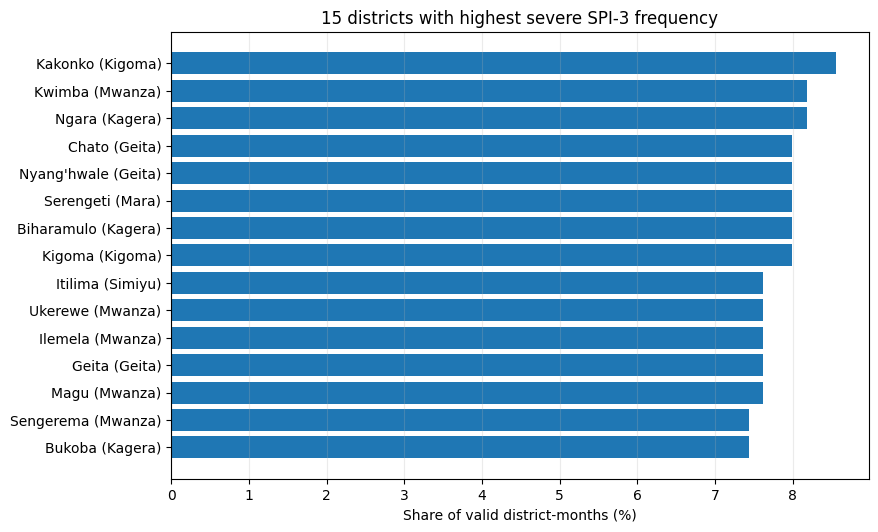

In [9]:
display(tables["district"].sort_values("severe_frequency", ascending=False).head(12))
fig = plot_districts(tables["district"], OUT / "figures" / "highest_frequency_districts.png")
plt.show(); plt.close(fig)

### When did severe drought occur?

Annual proportions identify widespread SPI-3 conditions. Individual monthly counts capture their timing within an annual period.

,year,severe_months,valid_spi_months,extreme_months,severe_frequency
22,2003,291.0,1800,145.0,0.161667
19,2000,258.0,1800,100.0,0.143333
12,1993,230.0,1800,98.0,0.127778
24,2005,225.0,1800,74.0,0.125
36,2017,215.0,1800,81.0,0.119444
18,1999,208.0,1800,67.0,0.115556
25,2006,197.0,1800,110.0,0.109444
16,1997,184.0,1800,87.0,0.102222
3,1984,164.0,1800,58.0,0.091111
34,2015,151.0,1800,70.0,0.083889


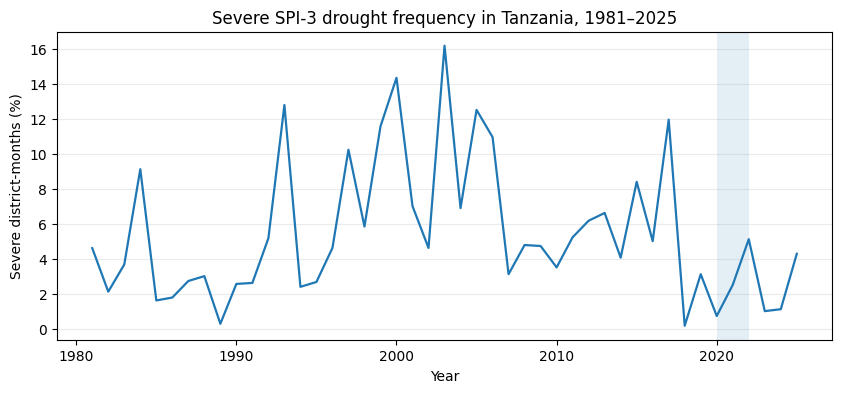

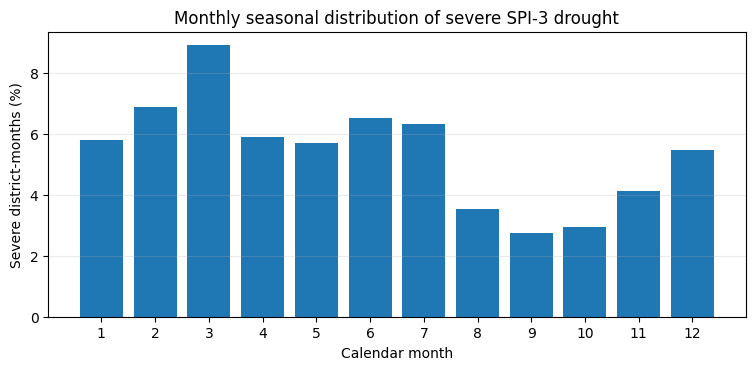

In [10]:
display(tables["annual"].nlargest(10, "severe_frequency"))
fig=plot_annual(tables["annual"], OUT / "figures" / "annual_severe_frequency.png")
plt.show(); plt.close(fig)
fig=plot_monthly(tables["calendar_month"], OUT / "figures" / "calendar_month_frequency.png")
plt.show(); plt.close(fig)

### Duration and severity

An episode is a maximal consecutive sequence of months at or below the chosen SPI-3 threshold within the same district. Missing SPI-3 or a month above the threshold ends an episode.

,district,region,start_month,end_month,duration_months,lowest_spi3
118,Nyamagana,Mwanza,1984-01-01,1984-07-01,7,-2.388088
1680,Tarime,Mara,2005-08-01,2006-02-01,7,-2.277428
117,Ukerewe,Mwanza,1984-01-01,1984-06-01,6,-2.414914
121,Misungwi,Mwanza,1984-02-01,1984-07-01,6,-2.229215
1161,Babati,Manyara,2000-02-01,2000-07-01,6,-2.499853
1166,Nyang'hwale,Geita,2000-02-01,2000-07-01,6,-2.597322
1681,Serengeti,Mara,2005-08-01,2006-01-01,6,-2.416385
120,Ilemela,Mwanza,1984-02-01,1984-06-01,5,-2.410646
126,Magu,Mwanza,1984-03-01,1984-07-01,5,-2.224027
131,Busega,Simiyu,1984-03-01,1984-07-01,5,-2.499701


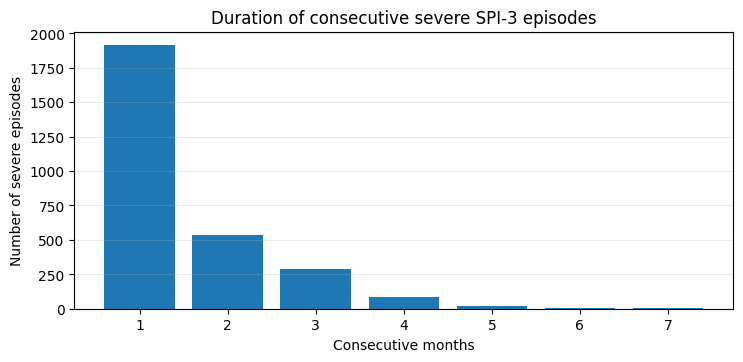

In [11]:
display(severe_episodes.nlargest(10, "duration_months")[["district","region","start_month","end_month","duration_months","lowest_spi3"]])
fig=plot_episode_duration(severe_episodes, OUT / "figures" / "severe_episode_durations.png")
plt.show(); plt.close(fig)

### District map

The choropleth uses NBS 2022 district polygons. Geographic plotting requires the optional `geopandas` package; all numerical analyses run without it.

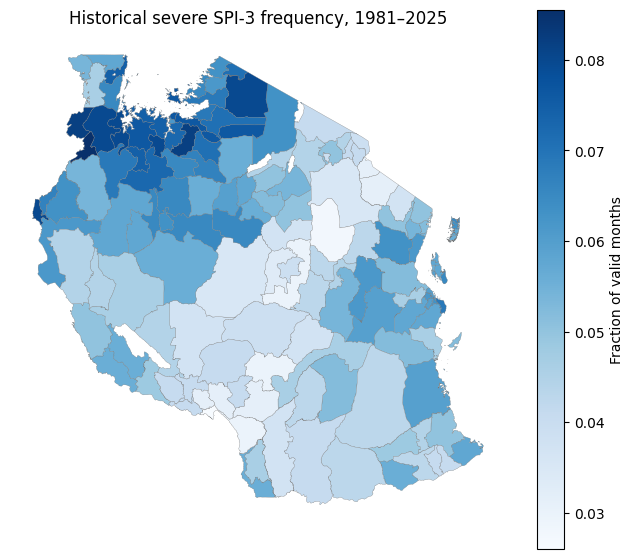

In [12]:
fig=plot_geographic(tables["district"], GEOGRAPHY, OUT / "maps" / "historical_severe_frequency_map.png")
if fig is None:
    print("Install optional geographic dependencies with: pip install -r requirements-maps.txt")
else:
    plt.show(); plt.close(fig)

### Northern Tanzania, 2021–2022

Rainfall totals are compared with 1981–2010 seasonal rainfall means. These seasonal deficits must not be confused with the monthly severe SPI-3 classification.

In [13]:
northern=northern_case_study(data)
display(northern.round(2))
print("Severe SPI-3 months in these three northern districts in 2020–2022:",
      int(classified.loc[classified.district.isin(["Longido","Monduli","Simanjiro"]) & classified.year.between(2020,2022),"is_severe"].sum()))
for name,t in tables.items(): t.to_csv(OUT / "tables" / f"{name}_drought_history.csv", index=False)
severe_episodes.to_csv(OUT / "tables" / "severe_drought_episode_register.csv", index=False)
all_drought_episodes.to_csv(OUT / "tables" / "drought_episode_register.csv", index=False)
northern.to_csv(OUT / "tables" / "northern_2021_2022_rainfall.csv", index=False)

,district,season,rainfall_mm,reference_rainfall_mm,percent_of_reference,last_month_spi3,months_with_severe_spi3
0,Longido,Vuli 2021,124.99,207.46,60.25,-0.74,0
1,Longido,Masika 2022,219.00,342.25,63.99,-1.10,0
2,Monduli,Vuli 2021,97.49,211.51,46.09,-0.93,0
3,Monduli,Masika 2022,240.41,362.02,66.41,-1.06,0
4,Simanjiro,Vuli 2021,92.12,181.67,50.71,-0.87,0
5,Simanjiro,Masika 2022,213.25,343.19,62.14,-1.47,0


Severe SPI-3 months in these three northern districts in 2020–2022: 0


### Interpretation

The SPI-3 reconstruction describes meteorological drought conditions in the supplied index. Reported pastoral drought impacts in 2020–2022 cannot be inferred from SPI-3 alone, especially where local severe thresholds were not crossed.

## 4. Seasonal Climatology: mathematical specification

**Objective.** Estimate district- and calendar-month-specific severe-drought probabilities from earlier historical observations.

$$\boxed{\hat p_{d,m}=\frac{D_{d,m}}{N_{d,m}}}$$

$D_{d,m}$ counts previous years in which district $d$ experienced severe SPI-3 drought in calendar month $m$. $N_{d,m}$ counts previous years with valid SPI-3 for that district/month. No weights, smoothing, satellite predictors or regression parameters are applied.

A forecast is undefined if $N_{d,m}=0$. Historical observations at or after the forecast issue date must never enter $D$ or $N$.

In [14]:
forecasts=forecast_table(data)
example=inspect_forecast(forecasts,"Nanyumbu","2020-04-01",3)
display(example)

,district_id,region,district,issue_month,target_month,horizon_months,calendar_month,historical_severe_years,historical_valid_years,predicted_probability,observed_spi3,observed_severe,severe_onset,latest_used_month_upper_bound
0,0905,Mtwara,Nanyumbu,2020-01-01,2020-04-01,3,4,4.0,39.0,0.102564,-1.768952,1,1,2019-04-01


### Worked calculation: Nanyumbu, April 2020

The forecast issued in January 2020 uses earlier April observations only.

$$\hat p_{\mathrm{Nanyumbu,Apr}}=\frac{4}{39}=0.10256\approx10.26\%.$$

The observed April 2020 SPI-3 was below $-1.5$, so the event subsequently met the severe-drought definition. This example is one forecast verification, not a model-wide accuracy estimate.

In [15]:
row=example.iloc[0]
D=int(row.historical_severe_years); N=int(row.historical_valid_years)
print(f"Historical count D = {D}; valid observations N = {N}")
print(f"D/N = {D}/{N} = {D/N:.8f} ({100*D/N:.2f}%)")
print(f"Issue: {row.issue_month:%Y-%m}; target: {row.target_month:%Y-%m}; observed SPI-3: {row.observed_spi3:.3f}")
assert D==4 and N==39
assert abs(row.predicted_probability-D/N)<1e-12
history=data[(data.district.eq("Nanyumbu")) & (data.month.dt.month==4) &
             (data.month.lt(pd.Timestamp("2020-01-01"))) & data[SPI_FIELD].notna()].copy()
history['historical_severe']=history[SPI_FIELD].le(-1.5).astype(int)
display(history[["month",SPI_FIELD,"historical_severe"]].tail(12))
assert int(history.historical_severe.sum())==D and len(history)==N

Historical count D = 4; valid observations N = 39
D/N = 4/39 = 0.10256410 (10.26%)
Issue: 2020-01; target: 2020-04; observed SPI-3: -1.769


,month,spi3_gamma_ref1981_2010,historical_severe
30027,2008-04-01,-0.078362,0
30039,2009-04-01,-0.938592,0
30051,2010-04-01,0.192518,0
30063,2011-04-01,1.544626,0
30075,2012-04-01,-0.515850,0
30087,2013-04-01,-1.990634,1
30099,2014-04-01,1.158860,0
30111,2015-04-01,-0.467202,0
30123,2016-04-01,0.463614,0
30135,2017-04-01,1.102073,0


### Historical probability register

A district-month table summarizes the historical information available through December 2019, before the selected 2020–2022 case-study period.

In [16]:
snapshot=climatology_snapshot(data,cutoff="2019-12-01")
display(snapshot.head(12))
print("District–calendar-month probabilities:",len(snapshot))
snapshot.to_csv(OUT / "predictions" / "district_month_climatology_as_of_2019.csv",index=False)

,district_id,region,district,calendar_month,D,N,probability
0,0202,Arusha,Arumeru,1,2,38,0.052632
1,0202,Arusha,Arumeru,2,3,38,0.078947
2,0202,Arusha,Arumeru,3,5,39,0.128205
3,0202,Arusha,Arumeru,4,1,39,0.025641
4,0202,Arusha,Arumeru,5,4,39,0.102564
5,0202,Arusha,Arumeru,6,5,39,0.128205
6,0202,Arusha,Arumeru,7,2,39,0.051282
7,0202,Arusha,Arumeru,8,2,39,0.051282
8,0202,Arusha,Arumeru,9,0,39,0.000000
9,0202,Arusha,Arumeru,10,0,39,0.000000


District–calendar-month probabilities: 1800


### Model assumptions and limitations

Seasonal Climatology assumes that historical frequency is informative about future seasonal risk. Its forecasts do not respond to current rainfall, soil moisture, NDVI or evolving drought conditions. Probabilities may be poorly calibrated if climate patterns change. A probability is not automatically an alert; warnings require a separately specified decision threshold.

## 5. Retrospective forecasting, 1–3 months ahead

**Objective.** Reconstruct what the baseline would have forecast at each past issue month, recording the prediction date, target date, numerator, denominator and subsequent observed SPI-3 value.

For target month $T$ and lead $h\in\{1,2,3\}$:

$$\hat p_{d,T\mid T-h}=\frac{D_{d,m(T),\mathrm{past}}}{N_{d,m(T),\mathrm{past}}}.$$

The preceding same-calendar-month observation is at least nine months before the issue month for these forecast leads. This implementation therefore uses historical observations known before each issue date.

In [17]:
forecasts=forecast_table(data)
print(f"Saved forecast records: {len(forecasts):,}")
print("Forecast horizons:",sorted(forecasts.horizon_months.unique()))
display(forecasts.head(9))
forecasts.to_csv(OUT / "predictions" / "seasonal_climatology_forecasts_2015_2025.csv",index=False)

Saved forecast records: 59,400
Forecast horizons: [np.int64(1), np.int64(2), np.int64(3)]


,district_id,region,district,issue_month,target_month,horizon_months,calendar_month,historical_severe_years,historical_valid_years,predicted_probability,observed_spi3,observed_severe,severe_onset,latest_used_month_upper_bound
0,0101,Dodoma,Kondoa,2014-12-01,2015-01-01,1,1,1.0,33.0,0.030303,-0.042829,0,0,2014-01-01
1,0101,Dodoma,Kondoa,2014-11-01,2015-01-01,2,1,1.0,33.0,0.030303,-0.042829,0,0,2014-01-01
2,0101,Dodoma,Kondoa,2014-10-01,2015-01-01,3,1,1.0,33.0,0.030303,-0.042829,0,0,2014-01-01
3,0102,Dodoma,Mpwapwa,2014-12-01,2015-01-01,1,1,1.0,33.0,0.030303,0.103148,0,0,2014-01-01
4,0102,Dodoma,Mpwapwa,2014-11-01,2015-01-01,2,1,1.0,33.0,0.030303,0.103148,0,0,2014-01-01
5,0102,Dodoma,Mpwapwa,2014-10-01,2015-01-01,3,1,1.0,33.0,0.030303,0.103148,0,0,2014-01-01
6,0103,Dodoma,Kongwa,2014-12-01,2015-01-01,1,1,1.0,33.0,0.030303,0.074418,0,0,2014-01-01
7,0103,Dodoma,Kongwa,2014-11-01,2015-01-01,2,1,1.0,33.0,0.030303,0.074418,0,0,2014-01-01
8,0103,Dodoma,Kongwa,2014-10-01,2015-01-01,3,1,1.0,33.0,0.030303,0.074418,0,0,2014-01-01


### District-level forecast lookup

Change `DISTRICT`, `TARGET_MONTH` and `LEAD_MONTHS` to examine a specific historical issue. The calculation is shown directly from the historical counts.

In [18]:
DISTRICT = "Nanyumbu"
TARGET_MONTH = "2020-04-01"
LEAD_MONTHS = 3
selected=inspect_forecast(forecasts,DISTRICT,TARGET_MONTH,LEAD_MONTHS)
if selected.empty:
    print("No valid historical forecast for the selected district, target and lead.")
else:
    r=selected.iloc[0]
    print(f"District: {r.district} | Issue: {r.issue_month:%Y-%m} | Target: {r.target_month:%Y-%m}")
    print(f"Historical severe / valid: {r.historical_severe_years}/{r.historical_valid_years}")
    print(f"Predicted severe-drought probability: {100*r.predicted_probability:.2f}%")
    print(f"Observed SPI-3: {r.observed_spi3:.3f} | Observed severe event: {bool(r.observed_severe)}")
    display(selected)

District: Nanyumbu | Issue: 2020-01 | Target: 2020-04
Historical severe / valid: 4.0/39.0
Predicted severe-drought probability: 10.26%
Observed SPI-3: -1.769 | Observed severe event: True


,district_id,region,district,issue_month,target_month,horizon_months,calendar_month,historical_severe_years,historical_valid_years,predicted_probability,observed_spi3,observed_severe,severe_onset,latest_used_month_upper_bound
0,0905,Mtwara,Nanyumbu,2020-01-01,2020-04-01,3,4,4.0,39.0,0.102564,-1.768952,1,1,2019-04-01


### Lead-time invariance

Seasonal Climatology depends on district and target calendar month, not the lead time. For a fixed target, the one-, two- and three-month probabilities must be equal. This establishes the model's advance *risk estimate*, not an event-specific detection lead time.

In [19]:
example_all=forecasts[(forecasts.district.eq("Nanyumbu")) &
                      (forecasts.target_month.eq(pd.Timestamp("2020-04-01")))].copy()
display(example_all[["issue_month","target_month","horizon_months","historical_severe_years","historical_valid_years","predicted_probability","observed_spi3"]])
assert example_all.predicted_probability.nunique()==1
assert (forecasts.latest_used_month_upper_bound<forecasts.issue_month).all()
print("The latest included historical observation precedes every forecast issue date.")

,issue_month,target_month,horizon_months,historical_severe_years,historical_valid_years,predicted_probability,observed_spi3
28515,2020-03-01,2020-04-01,1,4.0,39.0,0.102564,-1.768952
28516,2020-02-01,2020-04-01,2,4.0,39.0,0.102564,-1.768952
28517,2020-01-01,2020-04-01,3,4.0,39.0,0.102564,-1.768952


The latest included historical observation precedes every forecast issue date.


### Retrospective case-study forecasts

The 2020–2022 subset contains 150 districts × 36 target months × 3 horizons. The same target is evaluated at each lead separately; counts across leads must not be added as independent drought events.

In [20]:
case=forecasts[forecasts.target_month.dt.year.between(2020,2022)]
print("2020–2022 total rows (three leads):",len(case))
print("Unique district-month targets:",case[["district_id","target_month"]].drop_duplicates().shape[0])
display(case[case.district.isin(["Longido","Monduli","Simanjiro"])].head(12))

2020–2022 total rows (three leads): 16200
Unique district-month targets: 5400


,district_id,region,district,issue_month,target_month,horizon_months,calendar_month,historical_severe_years,historical_valid_years,predicted_probability,observed_spi3,observed_severe,severe_onset,latest_used_month_upper_bound
27021,0201,Arusha,Monduli,2019-12-01,2020-01-01,1,1,2.0,38.0,0.052632,2.002183,0,0,2019-01-01
27022,0201,Arusha,Monduli,2019-11-01,2020-01-01,2,1,2.0,38.0,0.052632,2.002183,0,0,2019-01-01
27023,0201,Arusha,Monduli,2019-10-01,2020-01-01,3,1,2.0,38.0,0.052632,2.002183,0,0,2019-01-01
27027,0203,Arusha,Longido,2019-12-01,2020-01-01,1,1,3.0,38.0,0.078947,2.124934,0,0,2019-01-01
27028,0203,Arusha,Longido,2019-11-01,2020-01-01,2,1,3.0,38.0,0.078947,2.124934,0,0,2019-01-01
27029,0203,Arusha,Longido,2019-10-01,2020-01-01,3,1,3.0,38.0,0.078947,2.124934,0,0,2019-01-01
27348,2104,Manyara,Simanjiro,2019-12-01,2020-01-01,1,1,3.0,38.0,0.078947,1.886569,0,0,2019-01-01
27349,2104,Manyara,Simanjiro,2019-11-01,2020-01-01,2,1,3.0,38.0,0.078947,1.886569,0,0,2019-01-01
27350,2104,Manyara,Simanjiro,2019-10-01,2020-01-01,3,1,3.0,38.0,0.078947,1.886569,0,0,2019-01-01
27471,0201,Arusha,Monduli,2020-01-01,2020-02-01,1,2,3.0,38.0,0.078947,1.824257,0,0,2019-02-01


## 6. Baseline performance evaluation

**Objective.** Quantify how well historical seasonal risk probabilities distinguish severe-drought months from non-severe months.

**Validation period:** 2015–2018. A warning threshold is selected by maximizing F2 on one-month validation targets only. **Retrospective case study:** 2020–2022. These years were previously analysed and are not a pristine, independent holdout set.

Forecast verification uses Brier Score, ROC-AUC, average precision, recall, precision and false warnings. Scores describe SPI-3 severe-drought months—not crop or livestock damage.

In [21]:
forecasts=forecast_table(data)
threshold,ranked=validation_threshold(forecasts)
print(f"Validation-selected warning threshold: {threshold:.1%}")
display(ranked.head(10))
ranked.to_csv(OUT / "metrics" / "validation_threshold_search.csv",index=False)

Validation-selected warning threshold: 5.5%


,threshold,f2_score,precision,recall,true_alerts,false_alerts
0,0.055,0.300064,0.085077,0.814815,374,4022
1,0.030,0.292573,0.080762,0.849673,390,4439
2,0.050,0.283505,0.078571,0.814815,374,4386
3,0.045,0.283505,0.078571,0.814815,374,4386
4,0.040,0.283505,0.078571,0.814815,374,4386
5,0.035,0.283505,0.078571,0.814815,374,4386
6,0.025,0.283254,0.073487,0.989107,454,5724
7,0.020,0.283254,0.073487,0.989107,454,5724
8,0.015,0.283254,0.073487,0.989107,454,5724
9,0.010,0.283254,0.073487,0.989107,454,5724


### Evaluation measures

The Brier Score is the average squared probability error:

$$BS=\frac{1}{n}\sum_{i=1}^{n}(\hat p_i-y_i)^2.$$

A smaller Brier Score is better. ROC-AUC measures discrimination; average precision summarizes precision-recall performance. False-warning totals depend on the chosen alert threshold and the number of forecast opportunities.

In [22]:
evaluation=evaluation_by_period(forecasts,threshold)
evaluation.to_csv(OUT / "metrics" / "model_evaluation.csv",index=False)
view=evaluation[evaluation.period.isin(["validation_2015_2018","case_study_2020_2022","retrospective_2023_2025"])]
display(view[["period","lead_months","forecasts","severe_district_months","roc_auc","brier_score","precision","recall","false_alerts","missed_drought_months"]].round(4))

,period,lead_months,forecasts,severe_district_months,roc_auc,brier_score,precision,recall,false_alerts,missed_drought_months
0,validation_2015_2018,1,7200,459,0.6276,0.0594,0.0851,0.8148,4022,85
1,validation_2015_2018,2,7200,459,0.6276,0.0594,0.0851,0.8148,4022,85
2,validation_2015_2018,3,7200,459,0.6276,0.0594,0.0851,0.8148,4022,85
6,case_study_2020_2022,1,5400,150,0.5502,0.0287,0.0351,0.5600,2307,66
7,case_study_2020_2022,2,5400,150,0.5502,0.0287,0.0351,0.5600,2307,66
8,case_study_2020_2022,3,5400,150,0.5502,0.0287,0.0351,0.5600,2307,66
9,retrospective_2023_2025,1,5400,115,0.6111,0.0225,0.0267,0.5826,2441,48
10,retrospective_2023_2025,2,5400,115,0.6111,0.0225,0.0267,0.5826,2441,48
11,retrospective_2023_2025,3,5400,115,0.6111,0.0225,0.0267,0.5826,2441,48


### Main case study: 2020–2022

Each forecast at a given horizon is one district-month prediction. For comparability, the confusion matrix below uses only the one-month lead. Baseline forecasts have identical risk probabilities at all three leads for each target.

,2020–2022 result
forecasts,5400.000000
severe_district_months,150.000000
severe_event_rate,0.027778
mean_predicted_probability,0.057563
brier_score,0.028744
roc_auc,0.550170
average_precision,0.031318
warning_threshold,0.055000
true_alerts,84.000000
false_alerts,2307.000000


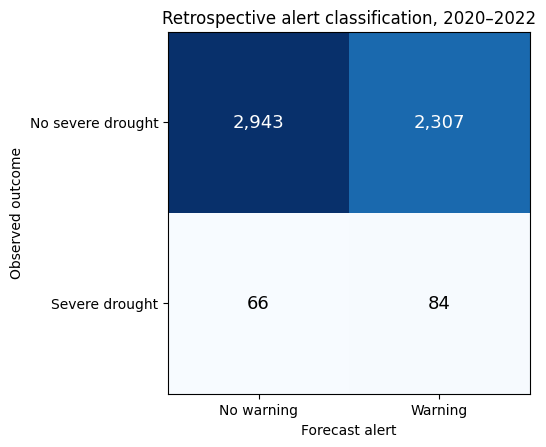

In [23]:
case=forecasts[(forecasts.target_month.dt.year.between(2020,2022)) & (forecasts.horizon_months==1)]
result=score_forecasts(case,threshold)
display(pd.DataFrame([result]).T.rename(columns={0:"2020–2022 result"}))
assert result["true_alerts"]==84 and result["false_alerts"]==2307
assert result["missed_drought_months"]==66 and result["correct_nonalerts"]==2943
fig=plot_confusion(result,OUT / "figures" / "2020_2022_warning_confusion.png")
plt.show();plt.close(fig)

### Observed drought versus historical risk

The baseline forecasts the historical seasonal event rate. It does not incorporate unusual rainfall conditions developing within 2020–2022.

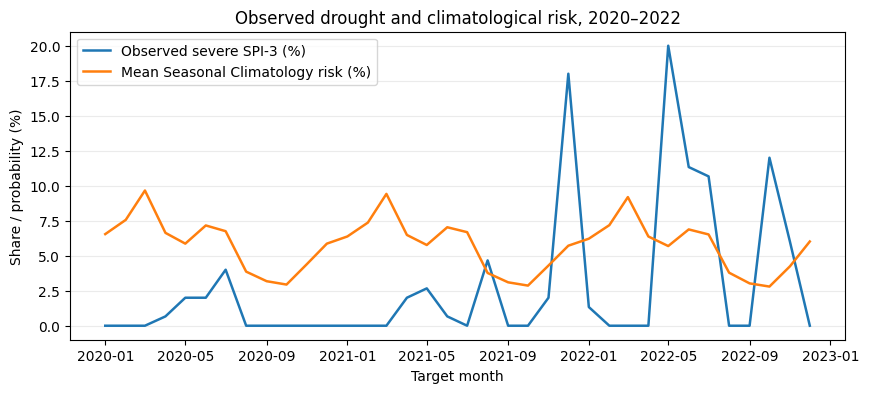

In [24]:
timeline=monthly_case_study(forecasts)
timeline.to_csv(OUT / "tables" / "2020_2022_observed_vs_forecast.csv",index=False)
fig=plot_case_study(timeline,OUT / "figures" / "2020_2022_observed_vs_baseline.png")
plt.show();plt.close(fig)

### Reliability and onset verification

Reliability compares forecast probabilities with observed frequencies. Onset is counted only when a severe SPI-3 month follows a preceding non-severe month. Onset verification is reported separately from all severe-drought months.

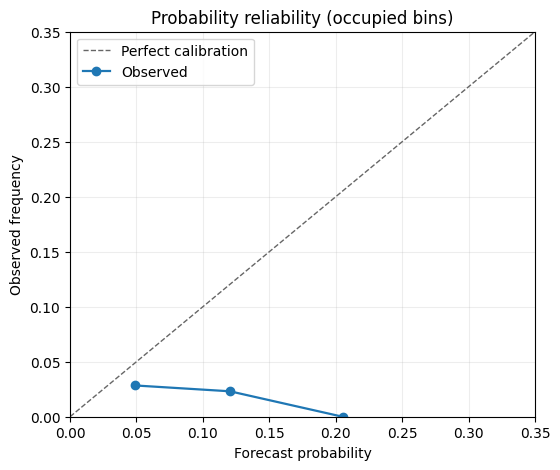

,band,mean_prediction,actual_rate,sample_size
0,"(-0.001, 0.1]",0.0489,0.0284,4748
1,"(0.1, 0.2]",0.1204,0.0231,649
2,"(0.2, 0.3]",0.2051,0.0000,3


,observed_new_severe_onsets,onset_months_with_warning,onset_months_without_warning
0,109,55,54


In [25]:
fig,reliability=plot_probability_bins(case,OUT / "figures" / "2020_2022_reliability.png")
plt.show();plt.close(fig)
display(reliability.round(4))
onsets=onset_warnings(forecasts,threshold)
display(pd.DataFrame([onsets]))

### Interpretation

The warning threshold was chosen to favor recall, generating substantial false alerts. Equal probability forecasts across leads should not be interpreted as evidence of three months of useful event-specific warning. None of these scores establish the time between warnings and agricultural impacts.

## 7. Results, interpretation and conclusion

**Study question:** How much advance drought-risk information can simple unweighted Seasonal Climatology provide at district level in Tanzania?

The baseline uses historical severe SPI-3 frequencies by district and calendar month. This notebook consolidates model construction, historical reconstruction and retrospective verification without adding any other forecast model.

In [26]:
summary=run_pipeline(INPUT,OUTPUT,plots=False)
qc=summary["data"]
history=summary["historical"]
case=summary["case_study_2020_2022"]
onset=summary["onset_2020_2022"]
print("Full reproducible project pipeline completed successfully.")
display(pd.DataFrame({"Indicator":["District-month records","Districts","Valid SPI-3","Severe SPI-3 months","Severe drought episodes","Longest severe episode (months)"],
    "Result":[qc["district_month_records"],qc["districts"],qc["valid_spi3"],history["severe_district_months"],history["severe_episodes"],history["longest_severe_episode_months"]]}))

Full reproducible project pipeline completed successfully.


,Indicator,Result
0,District-month records,81000
1,Districts,150
2,Valid SPI-3,80700
3,Severe SPI-3 months,4364
4,Severe drought episodes,2859
5,Longest severe episode (months),7


### Baseline forecast performance, 2020–2022

A warning threshold of 5.5% was selected from 2015–2018 validation targets. The 2020–2022 experiment contains 5,400 unique district-month observations at each lead.

In [27]:
main=pd.DataFrame({"Metric":["Observed severe district-months","Correct warnings","Missed drought observations","False warnings","Correct non-warnings","Recall","Precision","ROC-AUC","Brier Score"],
                   "Value":[case["severe_district_months"],case["true_alerts"],case["missed_drought_months"],case["false_alerts"],case["correct_nonalerts"],f"{case['recall']:.1%}",f"{case['precision']:.1%}",f"{case['roc_auc']:.3f}",f"{case['brier_score']:.4f}"]})
display(main)
print("Onset counts:",onset)

,Metric,Value
0,Observed severe district-months,150
1,Correct warnings,84
2,Missed drought observations,66
3,False warnings,2307
4,Correct non-warnings,2943
5,Recall,56.0%
6,Precision,3.5%
7,ROC-AUC,0.550
8,Brier Score,0.0287


Onset counts: {'observed_new_severe_onsets': 109, 'onset_months_with_warning': 55, 'onset_months_without_warning': 54}


### Findings

1. Seasonal Climatology provides reproducible district- and calendar-month-specific drought-risk probabilities without weights, smoothing or other model parameters.
2. Historical prevalence is not a reliable detector of rapidly changing climate conditions. The 2020–2022 ROC-AUC was approximately 0.55.
3. The validation-selected threshold identified 84 of 150 severe district-months, but issued 2,307 false warnings in the same period.
4. Forecast probabilities remain unchanged across the three lead times for a fixed district and target month. This represents an advance seasonal probability, not verified predictive awareness of a new drought onset.
5. The source SPI-3 classification does not identify severe months in Longido, Monduli or Simanjiro during 2020–2022, although seasonal rainfall deficits occurred. SPI-3 and independent impact evidence must be distinguished.

### Conclusion

Seasonal Climatology provides a transparent quantitative reference for district-level drought-risk forecasting. Its retrospective discriminatory power and alert precision are weak. The baseline is suitable for evaluating whether subsequent forecasting methods add value, but the evidence does not establish it as an operational early-warning service.

In [28]:
report=f"""# Group 3 — Seasonal Climatology results

## Data

- District-month records: {qc['district_month_records']:,}
- Districts: {qc['districts']}
- Valid SPI-3 values: {qc['valid_spi3']:,}
- Severe district-months (1981–2025): {history['severe_district_months']:,}
- Consecutive severe episodes: {history['severe_episodes']:,}

## Model

Unweighted seasonal frequency: p(d,m) = D(d,m)/N(d,m). Severe drought: SPI-3 <= -1.5.

## 2020–2022 retrospective verification (one lead)

- Observations: {case['forecasts']:,}
- Severe SPI-3 months: {case['severe_district_months']}
- Threshold selected on 2015–2018 validation: {summary['validation_selected_warning_threshold']:.1%}
- True alerts: {case['true_alerts']}
- Missed severe months: {case['missed_drought_months']}
- False alerts: {case['false_alerts']:,}
- Correct non-alerts: {case['correct_nonalerts']:,}
- Recall: {case['recall']:.2%}
- Precision: {case['precision']:.2%}
- ROC-AUC: {case['roc_auc']:.4f}
- Brier Score: {case['brier_score']:.5f}
- Onset months warned: {onset['onset_months_with_warning']} of {onset['observed_new_severe_onsets']}

## Limitations

This is a retrospective SPI-3 meteorological-drought evaluation. Seasonal probabilities do not adapt to current climate observations; 1–3-month lead equivalence is not a demonstrated early-detection lead time. Reference SPI-3 uses 1981–2010 climatological fits; the dataset applies 2022 district boundaries to earlier dates. No independently dated agricultural damage labels were used. The period 2020–2025 has previously been inspected and is not an untouched independent holdout.
"""
(ROOT / "docs" / "RESULTS.md").write_text(report,encoding="utf-8")
print("Reproducible results summary written to docs/RESULTS.md")

Reproducible results summary written to docs/RESULTS.md
